# Conditioning length and open-loop prediction

Checkpoint: `ls6hfsbu/00081600`. Compare **1, 5, 20 and 50 frames of conditioning** across the same **64 real episodes**.

All forecasts begin at the same environment frame. Their conditioning windows end at frame 49 and contain frames 49; 45–49; 30–49; or 0–49 respectively (zero-based). Recurrent state is reset at each window's start, so it retains no earlier history. At 50 fps these windows contain 0.02, 0.10, 0.40 and 1.00 seconds of observations.

After conditioning, each actor chooses actions from its own imagined state and the dynamics model receives no more images. The reference posterior continues to observe the real trajectory. Random draws are shared across the four branches, reducing sampling noise in the comparison.

At each future step, plot the mean across episodes of

$$\mathrm{KL}(q_{\mathrm{real}}\;\|\;p_{\mathrm{dynamics}}),$$

summed over categorical classes and averaged over latent factors (**nats per factor**). This compares learned distributions; it is not a pixel-distance score. Because the imagined actors may choose different actions, it includes different driving decisions as well as prediction error.


## Settings

The x-axis is steps after the common conditioning endpoint: step 1 corresponds to environment frame 50. All 64 episodes contribute at every plotted point; the curve stops at the shortest real episode. Shading gives pointwise 95% percentile intervals from 10,000 rliable bootstrap resamples of whole episodes, with times and contexts kept paired.

Re-running this notebook uses the saved trajectories. Enable `recompute_ci` to resample them without running environments. These intervals describe evaluation uncertainty for a fixed checkpoint, rather than variation across training seeds.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "pyproject.toml").is_file()
    and (parent / "notebooks/plot_generation").is_dir()
)
data_prefix = repo_root / "experiments/dreamer/divergence/ls6hfsbu-00081600-conditioning-64"
export_stem = repo_root / "assets/arc-conditioning-length"
recompute_ci = False
bootstrap_reps = 10_000
bootstrap_seed = 500_000

blk = "#343633"
off_white = "#F7F4EB"
line_styles = ["-", "--", "-.", ":"]
ci_alpha = 0.08
figure_size = (9.5, 4.4)

plt.rcParams.update({
    "font.family": "Routed Gothic", "font.style": "normal", "font.size": 11,
    "figure.facecolor": off_white, "axes.facecolor": off_white, "figure.dpi": 120,
    "text.color": blk, "axes.labelcolor": blk, "axes.edgecolor": blk,
    "xtick.color": blk, "ytick.color": blk, "svg.fonttype": "none",
})


In [2]:
report = json.loads(data_prefix.with_suffix(".json").read_text())
with np.load(data_prefix.with_suffix(".npz")) as archive:
    curves = archive["kl_curves"]
    episode_lengths = archive["episode_lengths"]

contexts = report["contexts"]
steps = np.asarray(report["steps"])
environment_steps = np.asarray(report["environment_steps"])
mean = np.asarray(report["mean"])
ci_low = np.asarray(report["ci_low"])
ci_high = np.asarray(report["ci_high"])
assert curves.shape[0] == report["num_episodes"] == 64
assert contexts == [1, 5, 20, 50]
assert steps[0] == 1
assert environment_steps[-1] == episode_lengths.min()
assert np.isfinite(curves[:, environment_steps]).all()
np.testing.assert_allclose(mean, curves[:, environment_steps].mean(axis=0, dtype=np.float64))
if recompute_ci:
    from dreamer.divergence import bootstrap_curve_mean

    mean, interval = bootstrap_curve_mean(
        curves[:, environment_steps], reps=bootstrap_reps, seed=bootstrap_seed,
    )
    ci_low, ci_high = interval

print(f"64 episodes; common origin: environment frame {report['forecast_origin_environment_step']}")
print(f"Open-loop steps: {steps[0]}–{steps[-1]}; environment frames: {environment_steps[0]}–{environment_steps[-1]}")
print("Mean KL at the first and final forecast steps (nats per factor):")
for index, context in enumerate(contexts):
    print(f"{context:2d} frames: {mean[0, index]:.3f} -> {mean[-1, index]:.3f} "
          f"[{ci_low[-1, index]:.3f}, {ci_high[-1, index]:.3f}]")


64 episodes; common origin: environment frame 49
Open-loop steps: 1–577; environment frames: 50–626
Mean KL at the first and final forecast steps (nats per factor):
 1 frames: 1.281 -> 1.772 [1.531, 2.032]
 5 frames: 0.658 -> 1.837 [1.565, 2.123]
20 frames: 0.542 -> 1.774 [1.518, 2.042]
50 frames: 0.173 -> 1.745 [1.484, 2.020]


## Four conditioning lengths

No smoothing is applied. Line patterns distinguish the four histories while preserving the ink and paper palette. Interpret short-term differences and long-term drift separately: this experiment tests one checkpoint and one forecast origin per episode.


Saved /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-conditioning-length.png


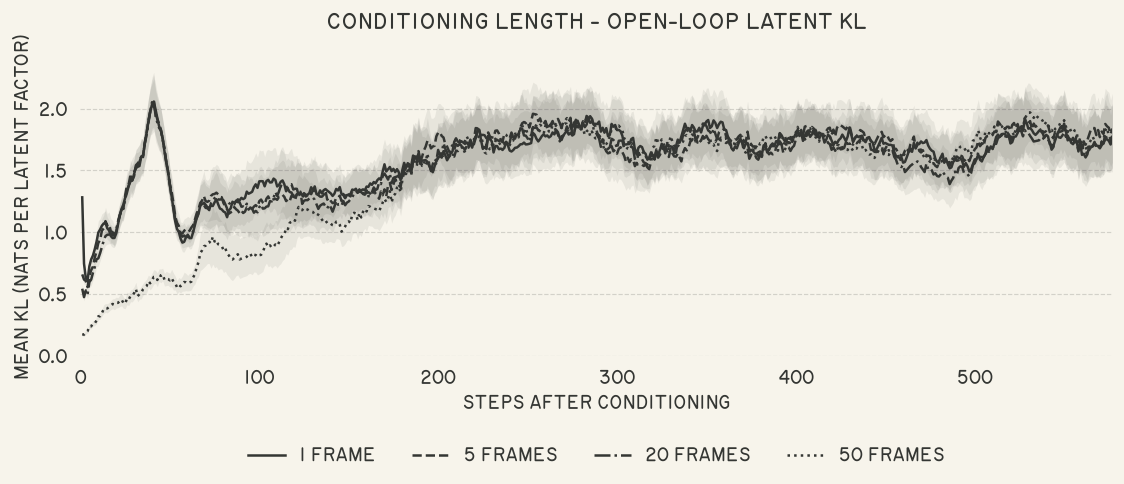

In [3]:
fig, ax = plt.subplots(figsize=figure_size)
for index, (context, linestyle) in enumerate(zip(contexts, line_styles, strict=True)):
    label = f"{context} FRAME{'S' if context != 1 else ''}"
    ax.fill_between(steps, ci_low[:, index], ci_high[:, index],
                    color=blk, alpha=ci_alpha, linewidth=0)
    ax.plot(steps, mean[:, index], color=blk, linewidth=1.5,
            linestyle=linestyle, label=label)

ax.set_title("CONDITIONING LENGTH - OPEN-LOOP LATENT KL", pad=18)
ax.set_xlabel("STEPS AFTER CONDITIONING")
ax.set_ylabel("MEAN KL (NATS PER LATENT FACTOR)")
ax.set_xlim(0, steps[-1])
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(MultipleLocator(100))
ax.set_axisbelow(True)
ax.grid(axis="y", color=blk, alpha=0.18, linestyle="--", linewidth=0.7)
ax.spines[:].set_visible(False)
ax.tick_params(axis="both", length=0, pad=8)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
plt.tight_layout()

export_stem.parent.mkdir(parents=True, exist_ok=True)
for extension in (".png", ".svg"):
    fig.savefig(export_stem.with_suffix(extension), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {export_stem.with_suffix('.png')}")
